In [2]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from src.dataset import load_dataset, split_dataset
from src.features import load_audio, normalize_duration

In [3]:
AUDIO_DIR = Path('../data/Audio_Files')
SHORDS_DIR = Path('../data/shords_dataset')
TARGET_DURATION = 2.0  # seconds — all samples normalized to this length

# Load both datasets with duration normalization (cut/pad to 2s)
features_audio, labels_audio = load_dataset(AUDIO_DIR, target_duration=TARGET_DURATION)
features_shords, labels_shords = load_dataset(SHORDS_DIR, target_duration=TARGET_DURATION)

# Harmonize label names (shords uses lowercase)
labels_shords = np.char.capitalize(labels_shords.astype(str))

# Combine
features = np.concatenate([features_audio, features_shords])
labels = np.concatenate([labels_audio, labels_shords])
print(f'Audio_Files:    {features_audio.shape[0]} samples')
print(f'shords_dataset: {features_shords.shape[0]} samples')
print(f'Combined:       {features.shape[0]} samples, {features.shape[1]} features')

le = LabelEncoder()
y = le.fit_transform(labels)

X_train_raw, X_test_raw, y_train, y_test = split_dataset(features, y)
print(f'Train: {X_train_raw.shape}, Test: {X_test_raw.shape}')
print(f'Classes: {le.classes_}')

Audio_Files:    859 samples
shords_dataset: 502 samples
Combined:       1361 samples, 25 features
Train: (1088, 25), Test: (273, 25)
Classes: ['Major' 'Minor']


## Scaling Experiment
Compare model performance with different feature scaling strategies: no scaling, StandardScaler, and MinMaxScaler.

In [4]:
scaling_methods = {
    'No Scaling': None,
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
}

test_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'SVM (RBF)': SVC(kernel='rbf'),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
}

scaling_results = {}
for scaler_name, scaler in scaling_methods.items():
    if scaler is not None:
        X_scaled = scaler.fit_transform(features)
    else:
        X_scaled = features.copy()

    row = {}
    for model_name, model in test_models.items():
        scores = cross_val_score(model, X_scaled, y, cv=5, scoring='accuracy')
        row[model_name] = f'{scores.mean():.4f} ± {scores.std():.4f}'
    scaling_results[scaler_name] = row

scaling_df = pd.DataFrame(scaling_results).T
scaling_df.index.name = 'Scaling'
print(scaling_df.to_string())

# Pick the best scaler for downstream use
best_scaler_name = max(scaling_results, key=lambda s: max(
    float(v.split(' ')[0]) for v in scaling_results[s].values()))
print(f'\nBest scaling strategy: {best_scaler_name}')

/home/bob/University/ML/Project/ChordClassifier/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/bob/University/ML/Project/ChordClassifier/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as sho

               Logistic Regression        SVM (RBF)    Random Forest
Scaling                                                             
No Scaling         0.5820 ± 0.0691  0.5827 ± 0.0347  0.7193 ± 0.0257
StandardScaler     0.5849 ± 0.0647  0.6466 ± 0.0645  0.7193 ± 0.0257
MinMaxScaler       0.5856 ± 0.0470  0.6334 ± 0.0411  0.7201 ± 0.0255

Best scaling strategy: MinMaxScaler


In [5]:
# Apply StandardScaler (standard choice) for all downstream sklearn models
scaler = MinMaxScaler()
X = scaler.fit_transform(features)
X_train = scaler.transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(),
    'SVM (RBF)': SVC(kernel='rbf'),
    'SVM (Linear)': SVC(kernel='linear'),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
}

results = {}
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5, scoring='accuracy')
    results[name] = {'mean': scores.mean(), 'std': scores.std(), 'scores': scores}
    print(f'{name:25s}  {scores.mean():.4f} ± {scores.std():.4f}')

results_df = pd.DataFrame({k: {'Accuracy': f"{v['mean']:.4f} ± {v['std']:.4f}"} for k, v in results.items()}).T
results_df

Logistic Regression        0.5856 ± 0.0470
KNN                        0.6319 ± 0.0212
SVM (RBF)                  0.6334 ± 0.0411
SVM (Linear)               0.6025 ± 0.0355
Random Forest              0.7201 ± 0.0255
Gradient Boosting          0.6775 ± 0.0319


,Accuracy
Logistic Regression,0.5856 ± 0.0470
KNN,0.6319 ± 0.0212
SVM (RBF),0.6334 ± 0.0411
SVM (Linear),0.6025 ± 0.0355
Random Forest,0.7201 ± 0.0255
Gradient Boosting,0.6775 ± 0.0319


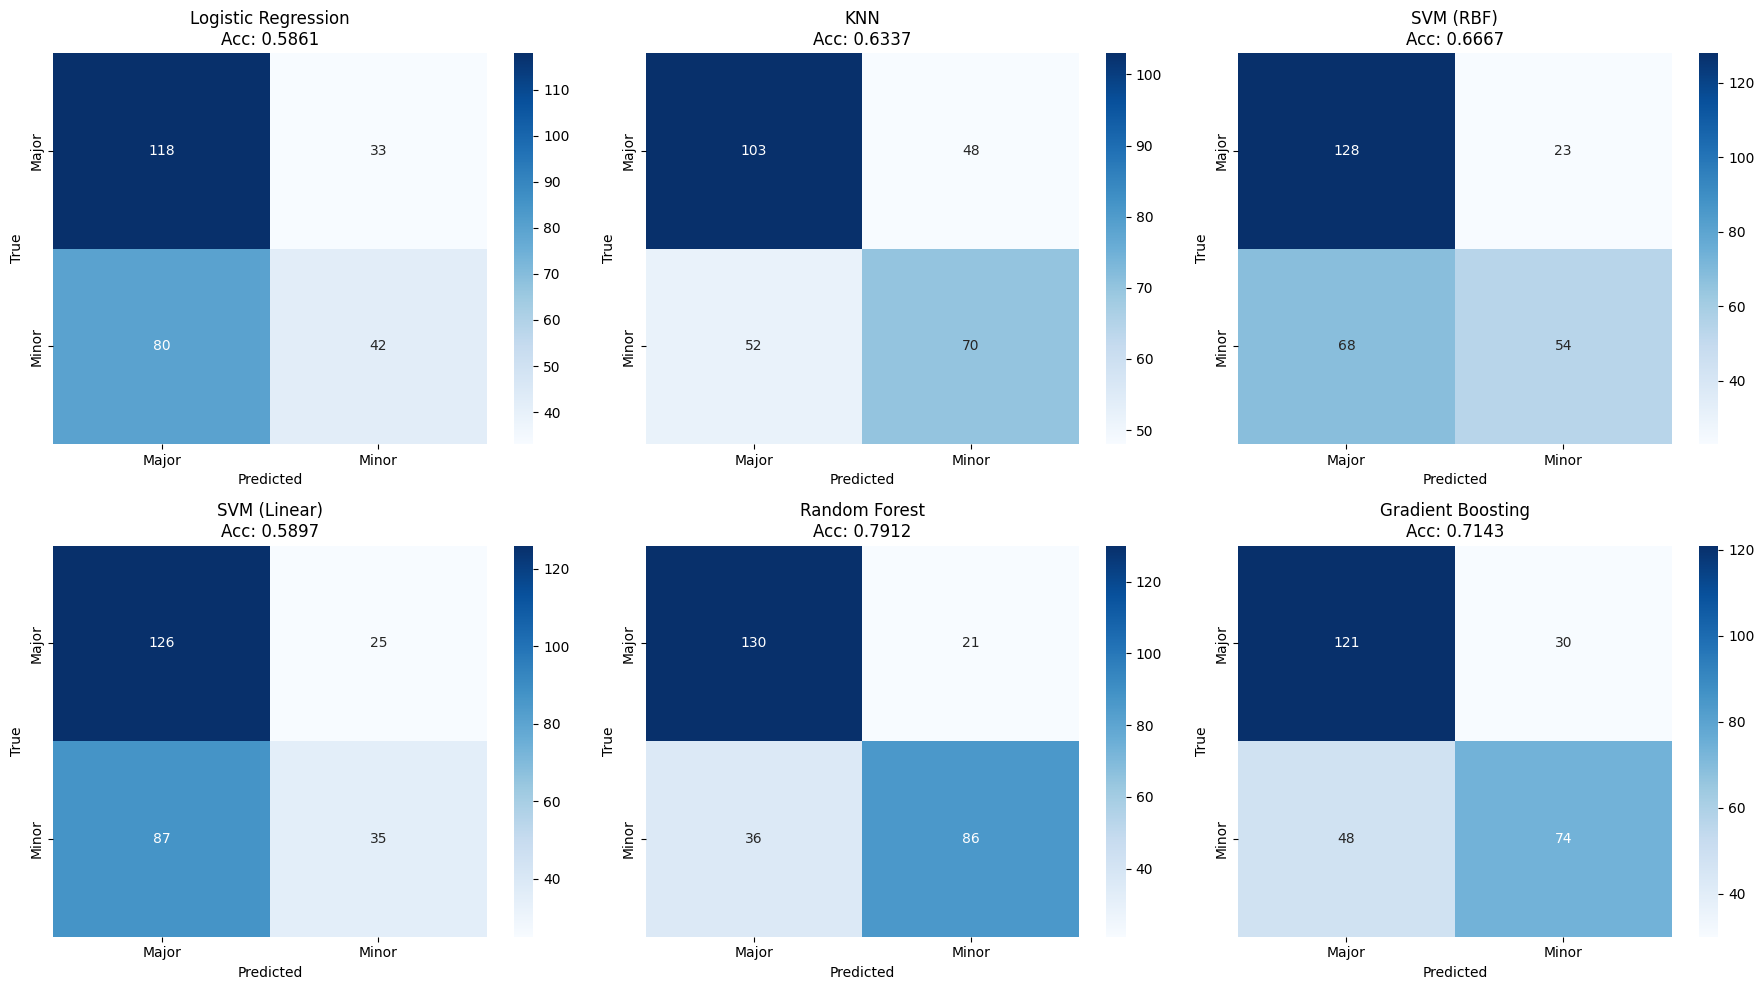

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, (name, model) in enumerate(models.items()):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=le.classes_, yticklabels=le.classes_)
    acc = accuracy_score(y_test, y_pred)
    axes[idx].set_title(f'{name}\nAcc: {acc:.4f}')
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('True')

plt.tight_layout()
plt.show()

In [7]:
best_name = max(results, key=lambda k: results[k]['mean'])
print(f'Best model from CV: {best_name}')

best_model = models[best_name]
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=le.classes_))

Best model from CV: Random Forest
              precision    recall  f1-score   support

       Major       0.78      0.86      0.82       151
       Minor       0.80      0.70      0.75       122

    accuracy                           0.79       273
   macro avg       0.79      0.78      0.79       273
weighted avg       0.79      0.79      0.79       273



In [8]:
param_grids = {
    'SVM': {
        'model': SVC(),
        'params': {
            'C': [0.1, 1, 10, 100],
            'kernel': ['rbf', 'linear'],
            'gamma': ['scale', 'auto'],
        }
    },
    'RF': {
        'model': RandomForestClassifier(random_state=42),
        'params': {
            'n_estimators': [50, 100, 200],
            'max_depth': [None, 10, 20],
            'min_samples_split': [2, 5],
        }
    },
    'KNN': {
        'model': KNeighborsClassifier(),
        'params': {
            'n_neighbors': [3, 5, 7, 11, 15],
            'weights': ['uniform', 'distance'],
            'metric': ['euclidean', 'manhattan'],
        }
    },
}

tuned_results = {}
for name, cfg in param_grids.items():
    gs = GridSearchCV(cfg['model'], cfg['params'], cv=5, scoring='accuracy', n_jobs=-1)
    gs.fit(X, y)
    tuned_results[name] = gs
    print(f'{name}: {gs.best_score_:.4f} | {gs.best_params_}')

SVM: 0.7370 | {'C': 100, 'gamma': 'scale', 'kernel': 'rbf'}
RF: 0.7274 | {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
KNN: 0.7090 | {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}


In [9]:
best_tuned = max(tuned_results, key=lambda k: tuned_results[k].best_score_)
best_gs = tuned_results[best_tuned]
print(f'Best tuned model: {best_tuned}')
print(f'Best CV score: {best_gs.best_score_:.4f}')
print(f'Best params: {best_gs.best_params_}')

best_gs.best_estimator_.fit(X_train, y_train)
y_pred_tuned = best_gs.best_estimator_.predict(X_test)
print(classification_report(y_test, y_pred_tuned, target_names=le.classes_))

Best tuned model: SVM
Best CV score: 0.7370
Best params: {'C': 100, 'gamma': 'scale', 'kernel': 'rbf'}
              precision    recall  f1-score   support

       Major       0.84      0.85      0.84       151
       Minor       0.81      0.80      0.80       122

    accuracy                           0.82       273
   macro avg       0.82      0.82      0.82       273
weighted avg       0.82      0.82      0.82       273



## Neural Networks

In [10]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from src.models import MLP, ChordCNN
from src.features import load_audio, extract_mel_spectrogram
import librosa

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cpu


### MLP on chroma + MFCC features

In [11]:
def train_nn(model, train_loader, val_loader, epochs=50, lr=1e-3):
    model = model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}

    for epoch in range(epochs):
        model.train()
        train_loss = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device).float()
            pred = model(xb).squeeze()
            loss = criterion(pred, yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        model.eval()
        val_loss = 0
        correct = 0
        total = 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device).float()
                pred = model(xb).squeeze()
                val_loss += criterion(pred, yb).item()
                predicted = (torch.sigmoid(pred) > 0.5).long()
                correct += (predicted == yb.long()).sum().item()
                total += yb.size(0)

        history['train_loss'].append(train_loss / len(train_loader))
        history['val_loss'].append(val_loss / len(val_loader))
        history['val_acc'].append(correct / total)

        if (epoch + 1) % 10 == 0:
            print(f'Epoch {epoch+1}/{epochs}  train_loss={history["train_loss"][-1]:.4f}  val_loss={history["val_loss"][-1]:.4f}  val_acc={history["val_acc"][-1]:.4f}')

    return history

In [14]:
X_train_t = torch.FloatTensor(X_train)
y_train_t = torch.LongTensor(y_train)
X_test_t = torch.FloatTensor(X_test)
y_test_t = torch.LongTensor(y_test)

train_ds = TensorDataset(X_train_t, y_train_t)
test_ds = TensorDataset(X_test_t, y_test_t)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(test_ds, batch_size=32)

mlp = MLP(input_dim=X_train.shape[1], hidden_dim=64, dropout=0.3)
print(mlp)
print(f'Parameters: {sum(p.numel() for p in mlp.parameters()):,}')

mlp_history = train_nn(mlp, train_loader, val_loader, epochs=130, lr=1e-3)

MLP(
  (net): Sequential(
    (0): Linear(in_features=25, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)
Parameters: 3,777
Epoch 10/300  train_loss=0.6797  val_loss=0.6823  val_acc=0.5714
Epoch 20/300  train_loss=0.6647  val_loss=0.6791  val_acc=0.5678
Epoch 30/300  train_loss=0.6360  val_loss=0.6634  val_acc=0.5897
Epoch 40/300  train_loss=0.5992  val_loss=0.6433  val_acc=0.5971
Epoch 50/300  train_loss=0.5812  val_loss=0.6270  val_acc=0.6264
Epoch 60/300  train_loss=0.5316  val_loss=0.6143  val_acc=0.6374
Epoch 70/300  train_loss=0.5202  val_loss=0.6065  val_acc=0.6703
Epoch 80/300  train_loss=0.5052  val_loss=0.5967  val_acc=0.6740
Epoch 90/300  train_loss=0.4826  val_loss=0.5890  val_acc=0.6593
Epoch 100/300  train_loss=0.4665  val_loss=0.5831  val_acc=0.6813
Epoch 110/

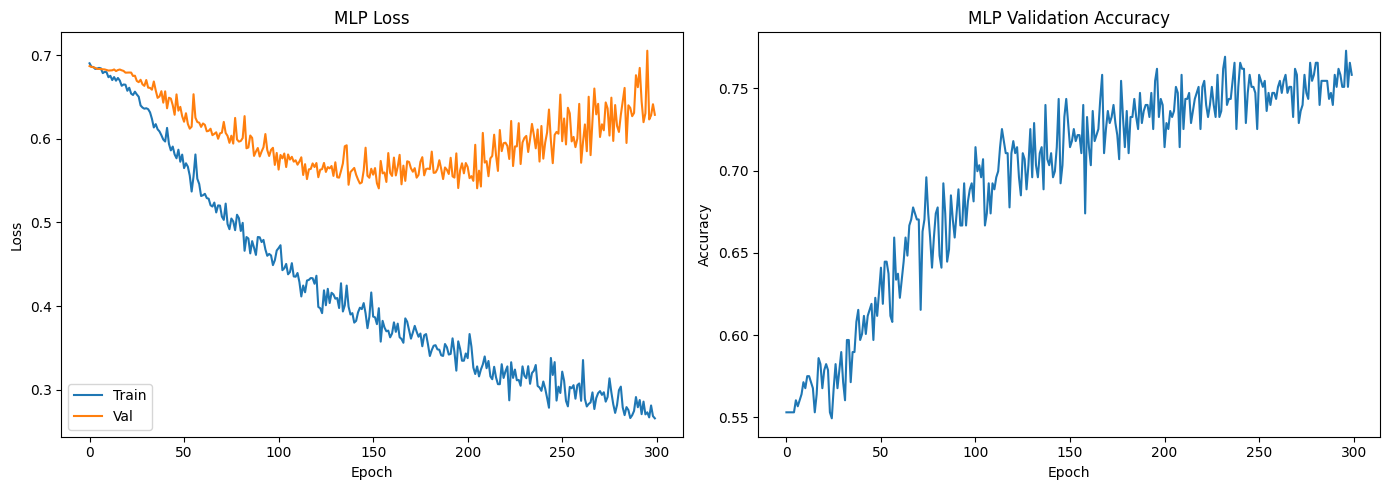

In [15]:
def plot_history(history, title=''):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(history['train_loss'], label='Train')
    axes[0].plot(history['val_loss'], label='Val')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title(f'{title} Loss')
    axes[0].legend()

    axes[1].plot(history['val_acc'])
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title(f'{title} Validation Accuracy')

    plt.tight_layout()
    plt.show()

plot_history(mlp_history, 'MLP')

### CNN on Mel Spectrograms

In [16]:
SR = 22050
FIXED_LENGTH = int(SR * TARGET_DURATION)  # 2 seconds

mel_features = []
mel_labels = []

for data_dir, label_map in [
    (Path('../data/Audio_Files'), {'Major': 0, 'Minor': 1}),
    (Path('../data/shords_dataset'), {'major': 0, 'minor': 1}),
]:
    for label_name, label_val in label_map.items():
        label_dir = data_dir / label_name
        if not label_dir.exists():
            continue
        for audio_file in sorted(label_dir.glob('*')):
            if audio_file.suffix not in ['.wav', '.mp3', '.flac', '.ogg']:
                continue
            y_audio, sr_audio = librosa.load(str(audio_file), sr=SR)
            y_audio = normalize_duration(y_audio, sr_audio, target_duration=TARGET_DURATION)
            mel = librosa.feature.melspectrogram(y=y_audio, sr=sr_audio, n_mels=128)
            mel_db = librosa.power_to_db(mel, ref=np.max)
            mel_features.append(mel_db)
            mel_labels.append(label_val)

mel_features = np.array(mel_features)
mel_labels = np.array(mel_labels)
print(f'Mel spectrograms shape: {mel_features.shape}')
print(f'Labels: {np.bincount(mel_labels)}')

Mel spectrograms shape: (1361, 128, 87)
Labels: [752 609]


In [17]:
from sklearn.model_selection import train_test_split

X_mel_train, X_mel_test, y_mel_train, y_mel_test = train_test_split(
    mel_features, mel_labels, test_size=0.2, random_state=42, stratify=mel_labels
)

X_mel_train_t = torch.FloatTensor(X_mel_train).unsqueeze(1)
X_mel_test_t = torch.FloatTensor(X_mel_test).unsqueeze(1)
y_mel_train_t = torch.LongTensor(y_mel_train)
y_mel_test_t = torch.LongTensor(y_mel_test)

train_mel_ds = TensorDataset(X_mel_train_t, y_mel_train_t)
test_mel_ds = TensorDataset(X_mel_test_t, y_mel_test_t)
train_mel_loader = DataLoader(train_mel_ds, batch_size=32, shuffle=True)
val_mel_loader = DataLoader(test_mel_ds, batch_size=32)

print(f'Train: {X_mel_train_t.shape}, Test: {X_mel_test_t.shape}')

Train: torch.Size([1088, 1, 128, 87]), Test: torch.Size([273, 1, 128, 87])


In [ ]:
cnn = ChordCNN()
print(cnn)
print(f'Parameters: {sum(p.numel() for p in cnn.parameters()):,}')

cnn_history = train_nn(cnn, train_mel_loader, val_mel_loader, epochs=50, lr=1e-3)

ChordCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
Parameters: 88,961
Epoch 10/50  train_loss=0.6832  val_loss=0.6851  val_acc=0.5872
Epoch 20/50  train_loss=0.6617  val_loss=0.6721  val_acc=0.6105
Epoch 30/50  train_loss=0.5920  val_loss=0.6389  val_acc=0.6512
Epoch 40/5

: 

: 

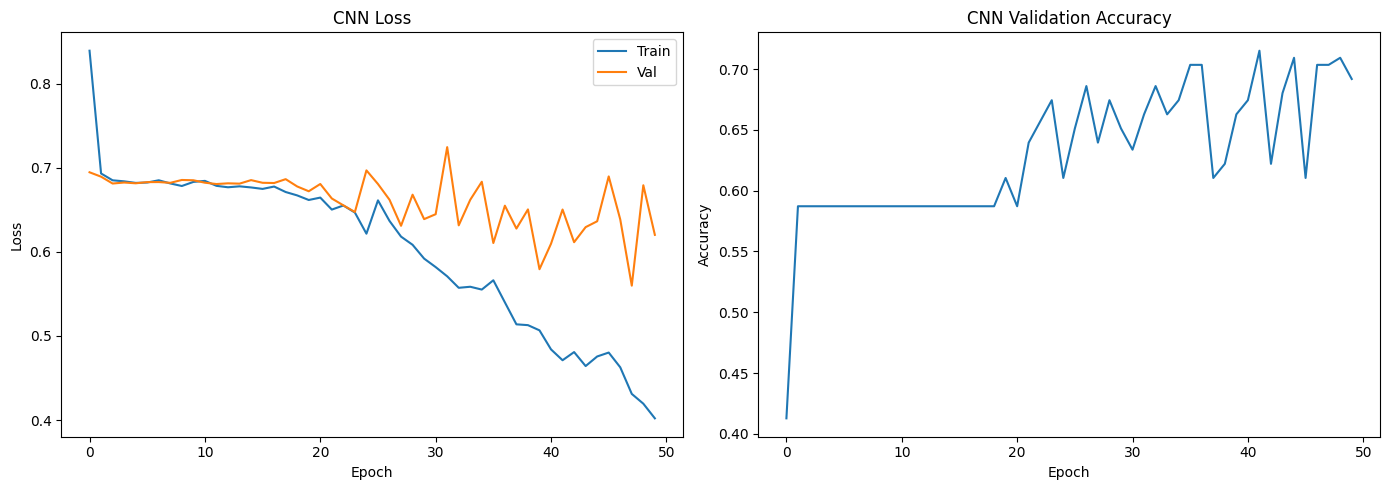

: 

: 

In [ ]:
plot_history(cnn_history, 'CNN')

### RNN (LSTM & GRU) on Mel Spectrograms

In [ ]:
from importlib import reload
import src.models
reload(src.models)
from src.models import ChordRNN

def train_rnn(model, train_loader, val_loader, epochs=100, lr=1e-3):
    model = model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=10, factor=0.5)

    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}

    for epoch in range(epochs):
        model.train()
        train_loss = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device).float()
            pred = model(xb).squeeze()
            loss = criterion(pred, yb)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            train_loss += loss.item()

        model.eval()
        val_loss = 0
        correct = 0
        total = 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device).float()
                pred = model(xb).squeeze()
                val_loss += criterion(pred, yb).item()
                predicted = (torch.sigmoid(pred) > 0.5).long()
                correct += (predicted == yb.long()).sum().item()
                total += yb.size(0)

        avg_val_loss = val_loss / len(val_loader)
        history['train_loss'].append(train_loss / len(train_loader))
        history['val_loss'].append(avg_val_loss)
        history['val_acc'].append(correct / total)
        scheduler.step(avg_val_loss)

        if (epoch + 1) % 20 == 0:
            print(f'Epoch {epoch+1}/{epochs}  train_loss={history["train_loss"][-1]:.4f}  val_loss={history["val_loss"][-1]:.4f}  val_acc={history["val_acc"][-1]:.4f}')

    return history

lstm = ChordRNN(n_mels=128, hidden_dim=64, num_layers=2, dropout=0.3, rnn_type='lstm')
print(lstm)
print(f'LSTM Parameters: {sum(p.numel() for p in lstm.parameters()):,}')

lstm_history = train_rnn(lstm, train_mel_loader, val_mel_loader, epochs=100, lr=1e-3)

ChordRNN(
  (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
  (rnn): LSTM(128, 64, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)
LSTM Parameters: 203,073
Epoch 20/100  train_loss=0.6368  val_loss=0.6651  val_acc=0.6453
Epoch 40/100  train_loss=0.4011  val_loss=0.5739  val_acc=0.7035
Epoch 60/100  train_loss=0.1995  val_loss=0.6032  val_acc=0.7791
Epoch 80/100  train_loss=0.0669  val_loss=1.0459  val_acc=0.7733
Epoch 100/100  train_loss=0.0355  val_loss=1.1983  val_acc=0.7616


: 

: 

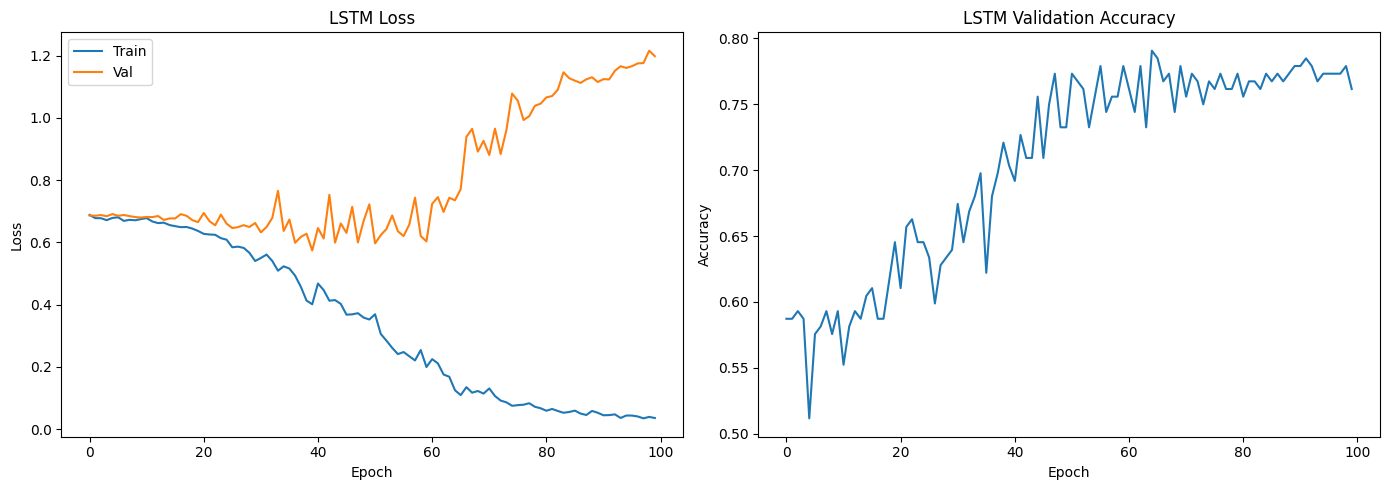

: 

: 

In [ ]:
plot_history(lstm_history, 'LSTM')

In [ ]:
gru = ChordRNN(n_mels=128, hidden_dim=64, num_layers=2, dropout=0.3, rnn_type='gru')
print(gru)
print(f'GRU Parameters: {sum(p.numel() for p in gru.parameters()):,}')

gru_history = train_rnn(gru, train_mel_loader, val_mel_loader, epochs=100, lr=1e-3)

ChordRNN(
  (norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
  (rnn): GRU(128, 64, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)
GRU Parameters: 153,409
Epoch 20/100  train_loss=0.5014  val_loss=0.5850  val_acc=0.7267
Epoch 40/100  train_loss=0.1893  val_loss=0.8334  val_acc=0.7616
Epoch 60/100  train_loss=0.0590  val_loss=1.1141  val_acc=0.7907
Epoch 80/100  train_loss=0.0430  val_loss=1.2970  val_acc=0.7849
Epoch 100/100  train_loss=0.0236  val_loss=1.3571  val_acc=0.7965


: 

: 

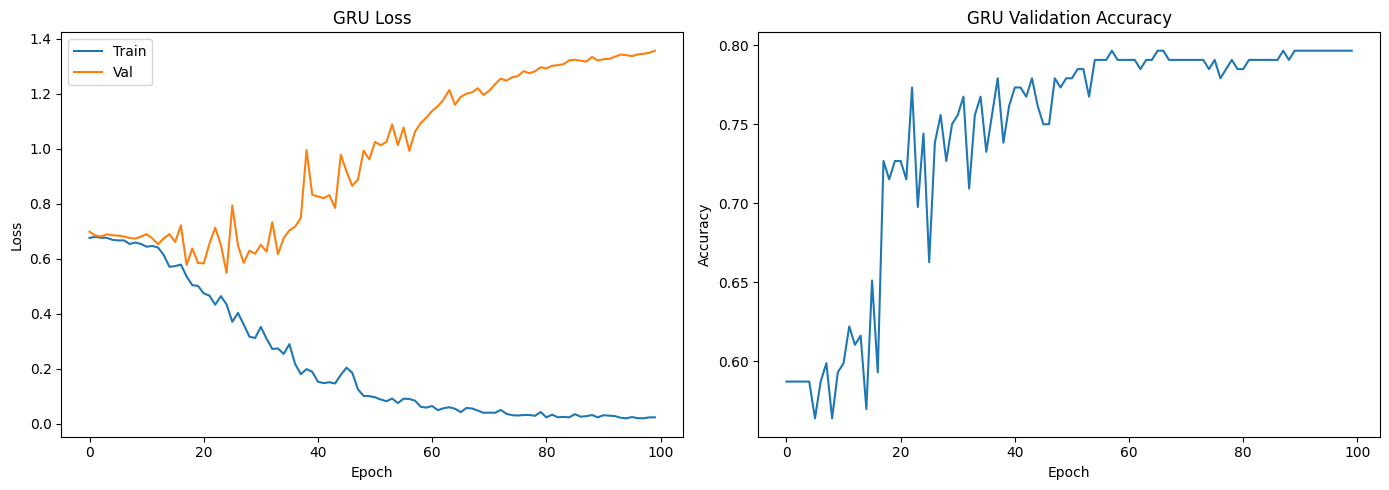

: 

: 

In [ ]:
plot_history(gru_history, 'GRU')

### Final Comparison

                 Model Test Accuracy
 GRU (Mel Spectrogram)        0.7965
                   MLP        0.7674
LSTM (Mel Spectrogram)        0.7616
         Random Forest        0.7500
     Gradient Boosting        0.7326
 CNN (Mel Spectrogram)        0.6919
             SVM (RBF)        0.6860
                   KNN        0.6512
          SVM (Linear)        0.6163
   Logistic Regression        0.5930


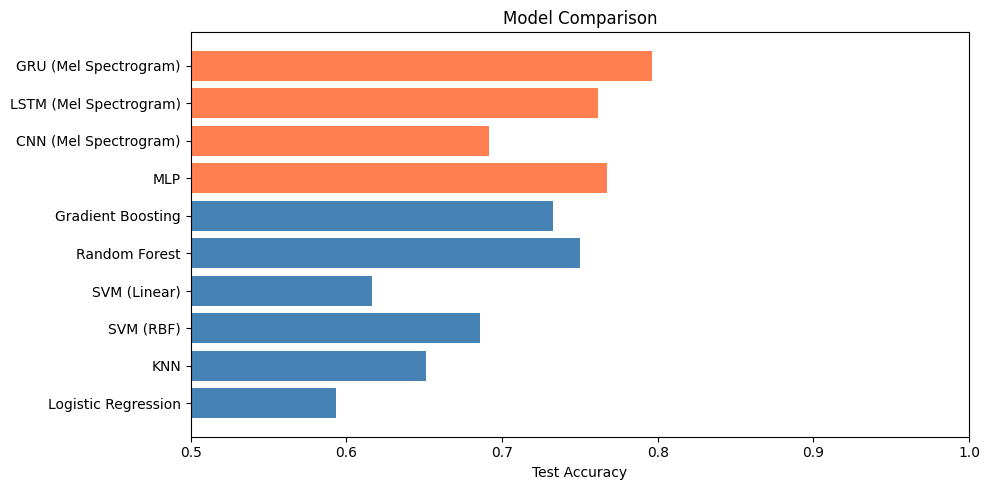

: 

: 

In [ ]:
mlp.eval()
cnn.eval()
lstm.eval()
gru.eval()

with torch.no_grad():
    mlp_pred = (torch.sigmoid(mlp(X_test_t.to(device)).squeeze()) > 0.5).cpu().numpy().astype(int)
    cnn_pred = (torch.sigmoid(cnn(X_mel_test_t.to(device)).squeeze()) > 0.5).cpu().numpy().astype(int)
    lstm_pred = (torch.sigmoid(lstm(X_mel_test_t.to(device)).squeeze()) > 0.5).cpu().numpy().astype(int)
    gru_pred = (torch.sigmoid(gru(X_mel_test_t.to(device)).squeeze()) > 0.5).cpu().numpy().astype(int)

all_results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    all_results[name] = accuracy_score(y_test, model.predict(X_test))

all_results['MLP'] = accuracy_score(y_test, mlp_pred)
all_results['CNN (Mel Spectrogram)'] = accuracy_score(y_mel_test, cnn_pred)
all_results['LSTM (Mel Spectrogram)'] = accuracy_score(y_mel_test, lstm_pred)
all_results['GRU (Mel Spectrogram)'] = accuracy_score(y_mel_test, gru_pred)

comparison_df = pd.DataFrame({
    'Model': list(all_results.keys()),
    'Test Accuracy': [f'{v:.4f}' for v in all_results.values()]
}).sort_values('Test Accuracy', ascending=False).reset_index(drop=True)

print(comparison_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
nn_keys = {'CNN', 'MLP', 'LSTM', 'GRU'}
colors = ['coral' if any(k in name for k in nn_keys) else 'steelblue' for name in all_results.keys()]
ax.barh(list(all_results.keys()), list(all_results.values()), color=colors)
ax.set_xlabel('Test Accuracy')
ax.set_title('Model Comparison')
ax.set_xlim(0.5, 1.0)
plt.tight_layout()
plt.show()